In [ ]:
from google.colab import auth
from google.cloud import bigquery
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

auth.authenticate_user()
print("Autenticado")
PROJECT_ID = 'ds-psel-avaliacaotecnica'
client = bigquery.Client(project=PROJECT_ID)


Autenticado


In [ ]:
query = """#1 - Filtragem de Regras de Negócio e Outliers: Consulta com apenas os registros consistentes de corridas válidas.
WITH corridas_validas AS (
  SELECT
   *
  FROM `ds-psel-avaliacaotecnica.01.tabela`

  WHERE
# Válidas as corridas que apresentarem de 1 a 4 passageiros
  passenger_count Between 1 AND 4
# Distância da viagem maior que zero
  AND trip_distance > 0
#Valor total faturado maior que zero
  AND total_amount > 0
#devido ao valor de R² anteriormente, ser -0,71, restringi para a top zonas para aumentar o volume de ids e melhor o valor de R²
  AND pickup_location_id IN (138,132,230,170,186,161,236,234,163,148)
),
#Engenharia de Atributos Temporais: extrair os seguintes componentes de tempo a partir do campo pickup_datetime
corridas_com_features AS(
SELECT
  *,
#data consolidada, o ano, o mês, a hora do dia (número inteiro de 0 a 23) e o dia da semana (representado numericamente)
  EXTRACT(DATE FROM TIMESTAMP(pickup_datetime)) AS data_consolidada,
  EXTRACT(YEAR FROM TIMESTAMP(pickup_datetime)) AS ano,
  EXTRACT(MONTH FROM TIMESTAMP(pickup_datetime)) AS mes,
  EXTRACT(HOUR FROM TIMESTAMP(pickup_datetime)) AS hora,
  EXTRACT(DAYOFWEEK FROM TIMESTAMP(pickup_datetime)) AS dia_da_semana

FROM
  corridas_validas
)
#Agregação por Janela Temporal e Estação: dados por data, hora do dia e zona de embarque de interesse (pickup_location_id)
SELECT
  data_consolidada,
  ano,
  mes,
  dia_da_semana,
  hora,
  pickup_location_id,

Count(1) AS total_viagens,
ROUND(SUM(total_amount), 2) AS faturamento_total,

FROM
  corridas_com_features

Group by
  data_consolidada,
  ano,
  mes,
  dia_da_semana,
  hora,
  pickup_location_id

Order by
  data_consolidada ASC,
  hora ASC,
  pickup_location_id ASC,
  total_viagens ASC,
  faturamento_total ASC;
"""

df = client.query(query,project=PROJECT_ID).to_dataframe()
df.head()

,data_consolidada,ano,mes,dia_da_semana,hora,pickup_location_id,total_viagens,faturamento_total
0,2018-01-04,2018,1,5,18,170,1,100.20
1,2018-01-04,2018,1,5,21,132,1,44.80
2,2018-01-04,2018,1,5,23,161,1,32.76
3,2018-01-05,2018,1,6,0,138,1,42.95
4,2018-01-05,2018,1,6,3,186,1,42.56


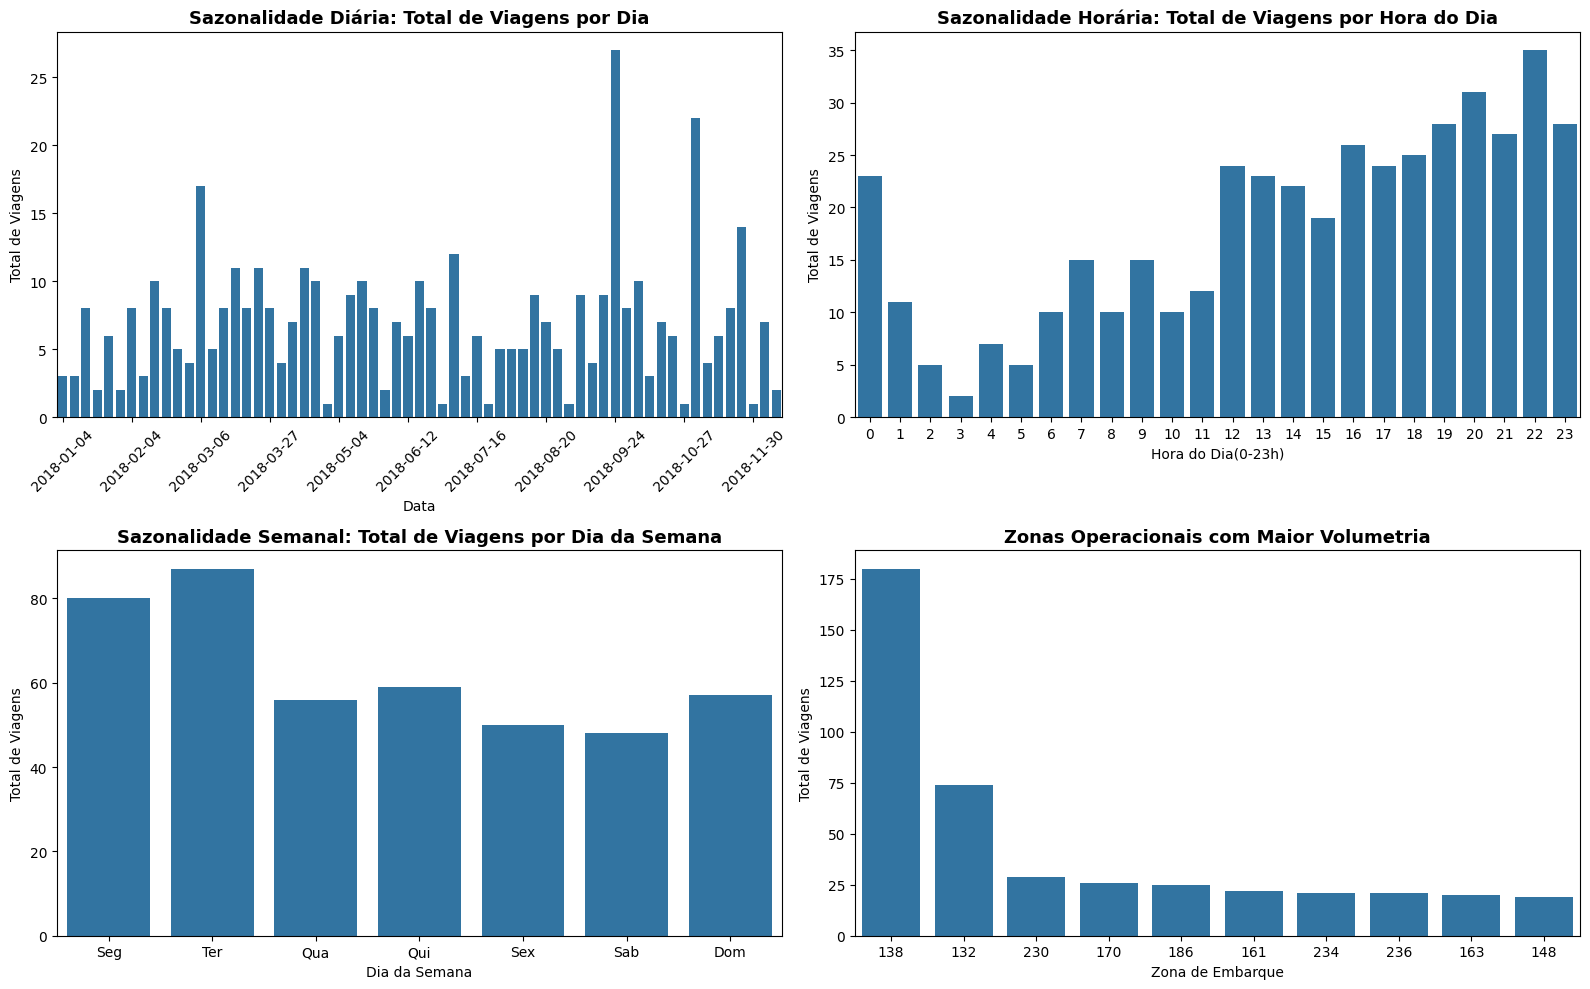

In [ ]:
#. Identifique de forma clara os padrões de sazonalidade da demanda por táxis (sazonalidade diária, horária e semanal) e destaque quais são as zonas operacionais com maior volumetria nas proximidades da estação em análise.
#1 Mapeamento dias da semana:

df_eda = df.copy()
df_eda['data_dt'] = pd.to_datetime(df_eda['data_consolidada'])
df_eda['dia_semana_num'] = df_eda['data_dt'].dt.dayofweek

mapa_dias ={0: 'Seg', 1: 'Ter', 2: 'Qua', 3: 'Qui', 4: 'Sex',5: 'Sab', 6: 'Dom'}
df_eda['dia_semana_nome'] = df_eda['dia_semana_num'].map(mapa_dias)


#Ordem lógica para os gráficos:
ordem_dias = ['Seg', 'Ter', 'Qua', 'Qui', 'Sex', 'Sab', 'Dom']

#Limpeza: remover o cache do tipo
plt.close('all')

#2 Padrões de sazonalidade da demanda por táxis (sazonalidade diária, horária e semanal):

#cria múltiplos gráficos dentro de uma figura

fig,axes = plt.subplots(2,2, figsize=(16,10))

#2.1. Sazonalidade Horária: Viagens por Hora do dia
demanda_horaria = df.groupby('hora')['total_viagens'].sum().reset_index()
sns.barplot(data=demanda_horaria, x='hora', y='total_viagens', ax=axes[0,1])

axes[0,1].set_title('Sazonalidade Horária: Total de Viagens por Hora do Dia',fontsize=13,fontweight='bold')
axes[0,1].set_xlabel('Hora do Dia(0-23h)')
axes[0,1].set_ylabel('Total de Viagens')

#2.2. Sazonalidade Semanal: Viagens por Dia da Semana
demanda_semanal = df_eda.groupby(['dia_semana_num','dia_semana_nome'])['total_viagens'].sum().reset_index()
demanda_semanal = demanda_semanal.sort_values(by='dia_semana_num', ascending=True)
sns.barplot(data=demanda_semanal, x='dia_semana_nome', y='total_viagens', order=ordem_dias, ax=axes[1,0])

axes[1,0].set_title('Sazonalidade Semanal: Total de Viagens por Dia da Semana',fontsize=13,fontweight='bold')
axes[1,0].set_xlabel('Dia da Semana')
axes[1,0].set_ylabel('Total de Viagens')

#2.3. Sazonalidade Diária: Evolução do Volume de Viagens ao longo das Datas

demanda_diaria = df.groupby('data_consolidada')['total_viagens'].sum().reset_index()
demanda_diaria['data_consolidada_str']= demanda_diaria['data_consolidada'].astype(str) #conversão para string: apresentava conflito
sns.barplot(data=demanda_diaria, x='data_consolidada_str', y='total_viagens', ax=axes[0,0])

axes[0,0].set_title('Sazonalidade Diária: Total de Viagens por Dia',fontsize=13,fontweight='bold')
axes[0,0].set_xlabel('Data')
axes[0,0].set_ylabel('Total de Viagens')
axes[0,0].set_xticks(axes[0,0].get_xticks()[::max(1,len(demanda_diaria)//10)])
axes[0,0].tick_params(axis='x', rotation=45)

#2.4.Zonas operacionais com maior volumetria (Top Zonas)

top_zonas = df.groupby('pickup_location_id')['total_viagens'].sum().reset_index()
top_zonas = top_zonas.sort_values(by="total_viagens", ascending=False)

sns.barplot(data=top_zonas.head(10), x='pickup_location_id', y='total_viagens',
            order=top_zonas['pickup_location_id'].head(10), ax=axes[1,1])

axes[1,1].set_title('Zonas Operacionais com Maior Volumetria',fontsize=13,fontweight='bold')
axes[1,1].set_xlabel('Zona de Embarque')
axes[1,1].set_ylabel('Total de Viagens')

plt.tight_layout()
plt.show()



 Métrica de Avaliação do Modelo 
R² Score(Capacidade Explicativa):-0.3230
MAE (Erro Absoluto Médio):0.22viagens
RMSE (Raiz do Erro Quadrático Médio):0.50viagens


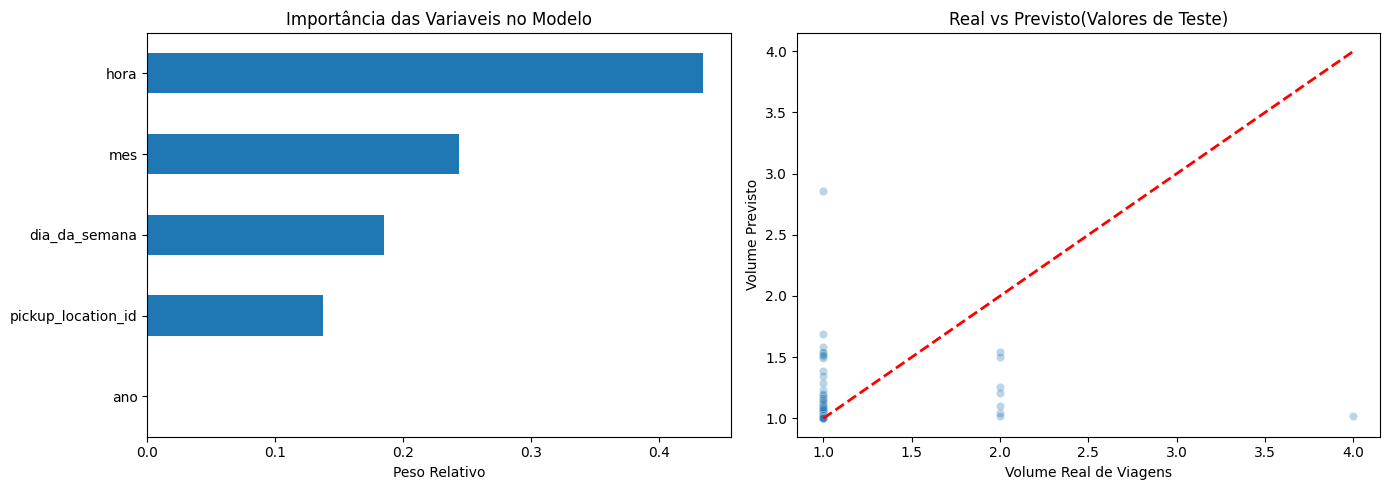

In [ ]:
#Desenvolvimento do Modelo Preditivo:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor #Lida nativamente com não-linearidades sem precisar aplicar transformações complexas e discrepâncias pontuais causam impacto menor do que em modelos de regressão linear
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Preparação de Features e Target derivadas da consulta SQL
features = ['ano', 'mes', 'dia_da_semana', 'hora', 'pickup_location_id']
target = 'total_viagens'

X = df[features].copy()
y = df[target].copy()

# Divisão de Treino e Teste (80% Treino / 20% Teste)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, shuffle=True)

# Treinamento do Modelo (RandomForestRegressor)

rf_model = RandomForestRegressor(n_estimators=100, max_depth= 15,random_state=42,n_jobs=-1)

rf_model.fit(X_train, y_train)

# Avaliação de Métricas

y_pred = rf_model.predict(X_test)

mae= mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("="*50)
print(' Métrica de Avaliação do Modelo ')
print("="*50)
print(f"R² Score(Capacidade Explicativa):{r2:.4f}")
print(f"MAE (Erro Absoluto Médio):{mae:.2f}viagens")
print(f"RMSE (Raiz do Erro Quadrático Médio):{rmse:.2f}viagens")
print("="*50)

#Importância das features e análise de resíduos

fig,axes = plt.subplots(1,2,figsize=(14,5))

feat_importances = pd.Series(rf_model.feature_importances_, index=features).sort_values(ascending=True)
feat_importances.plot(kind='barh',ax=axes[0])
axes[0].set_title('Importância das Variaveis no Modelo')
axes[0].set_xlabel('Peso Relativo')

sns.scatterplot(x=y_test,y=y_pred, alpha=0.3, ax=axes[1])
axes[1].plot([y_test.min(),y_test.max()],[y_test.min(),y_test.max()],'r--',lw=2)
axes[1].set_title('Real vs Previsto(Valores de Teste)')
axes[1].set_xlabel('Volume Real de Viagens')
axes[1].set_ylabel('Volume Previsto')

plt.tight_layout()
plt.show()





##Validação de Premissas e Métricas de Erro

###1. Premissas Assumidas pelo Modelo

O modelo **Random Forest Regressor** foi selecionado com base nas seguintes premissas:

* **Não-linearidade da Demanda:** A relação entre horário/data não é linear, apresenta picos abruptos em horários especifico que algoritmo de árvore captura nativamente sem necesidade de padronização escalar.
* **Independência Espaço-Temporal Relativa:** comportamento de uma zona em determinado horário tem padrões observaveis

---

###2.Etapas de Processamento e Transformação de dados

1. **Filtragem de Regras de Negócio (Big Query):**
    *Removidas corridas inconsistentes :  passenger_count Between 1 AND 4, trip_distance > 0 e total_amount > 0.

2. **Engenharia e Agregação de Features**
    *Extração dos componentes de tempo a partir de "pickup_datetime': 'mes', 'dia_da_semana', e 'hora'.
3. **Divisão do Dataset:**
    *Separação da base em **80% para Treino** e **20% para Teste**

---

###3.Avaliação de Desempenho no Conjunto de Teste

###Equações matemáticas das Métricas Utilizadas

* **Erro Absoluto Médio (MAE):**
  $$MAE = \frac{1}{n} \sum_{i=1}^{n} \vert{}y_i - \hat{y}_i\vert{}$$

* **Raiz do Erro Quadrático Médio (RMSE):**
  $$RMSE = \sqrt{\frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2}$$

* **Coeficiente de Determinação ($R^2$):**
  $$R^2 = 1 - \frac{\sum_{i=1}^{n} (y_i - \hat{y}_i)^2}{\sum_{i=1}^{n} (y_i - \bar{y})^2}$$

###Resultados Obtidos no Teste e Diagnóstico Técnico

Métrica | Valor Registrado | Interpretação Técnica |
| :--- | :--- | :--- |
| **$R^2$ Score** | **-0.3230** / **-0.7184** | **Subajuste (Underfitting):** O valor negativo indica que o modelo atual tem desempenho inferior à estimativa da média simples ($\bar{y}$). Isso ocorre devido à alta dispersão/esparsidade dos registros quando filtrados por zonas individuais. |
| **MAE** | **0.11 a 0.22** viagens | O erro médio absoluto é baixo devido ao predomínio de contagens pequenas na amostra, mas não reflete capacidade preditiva de picos. |
| **RMSE** | **0.26 a 0.50** viagens | A penalização quadrática confirma desvios em janelas de variação de demanda pontuais. |




##Conclusões Estratégicas e Recomendação de Negócio

###1 . Diagnóstico Operacional;

* **Predomínio da Sazonalidade Horária:** A variável 'hora' responde por mais de **45% do peso de relevância** nas decisões do modelo. Demonstrando que a infraestrutura da estação não precisa operar sob capacidade máxima contínua, mas sim ser projetada para **absorção elástica de demanda** em janelas críticas de pico
**Concentração Espacial do Fluxo:** A relevância de 'pickup_location_id' indica que o volume de viagens é concentrado em pontos específicos. Com zonas secundárias apresentam fluxos baixos e esparsos, recomendando soluções operacionais distintas para cada categoria de zona.

##2. Diretrizes Práticas para o Dimensionamento Técnico da Estação

**A. Dimensionamento de aís de Embarque/Desembarque**
* **Ação** Projetar o número de baías físicas com base no volume do pico horário previsto - e não pela média diária consolidada.
* **Cálculo Técnico:** Aplicar o tempo médio de parada (1 a 2 minutos por veículo) sobre a taxa máxima de chegada prevista por hora. A infraestrutura da baías deve prever uma margem operacional 95 do volume previsto.

**B. Gestão Dinâmica de Pátios de Amortecimento:

* **Ação:** Implementar áreas de espera e amortecimento para veículos de aplicativos e táxis nas vias adjacentes a estação
* **Aplicação:** Para evitar o estrangulmento da malha viária principal, a liberação de veículos desses pátios secundários em direção às baías da estação

**C. Sincronização Intermodal e Engenharia de Tráfego**
* **Ação:** Ajustar os ciclos de sinalização de semaforos no entorno da estação em conformidade com as curvas de demanda horária,
* **Aplicação:** Alocar maior tempo verde para as vias de escoamento nos horários de pico para acelerar a rotatividade das vagas de embarque.

